# EduPredict: Final Logistic Regression Risk Model
**Target:** `pass_status`  
**Encoding:** Pass = 0, Fail = 1  
**Selected model:** Tuned Logistic Regression  
**Selection reason:** Highest recall for the Fail class among the compared models.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, brier_score_loss
)


In [5]:
df = pd.read_csv(
    r"C:\Users\nadee\Downloads\student_exam_performance.csv"
)

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicated student IDs:", df["student_id"].duplicated().sum())
print("Unique student IDs:", df["student_id"].nunique())
print("Missing target values before cleaning:", df["pass_status"].isna().sum())
print(df["pass_status"].value_counts(dropna=False))


Dataset shape: (100000, 44)
Duplicate rows: 0
Duplicated student IDs: 0
Unique student IDs: 100000
Missing target values before cleaning: 0
pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64


In [6]:
df["pass_status"] = (
    df["pass_status"].astype("string").str.strip().str.lower()
)

df["pass_status"] = df["pass_status"].map({"pass": 0, "fail": 1})

print("Missing target values after encoding:", df["pass_status"].isna().sum())

df = df.dropna(subset=["pass_status"]).copy()
df["pass_status"] = df["pass_status"].astype(int)

print("Final target distribution:")
print(df["pass_status"].value_counts())
print("Final target distribution (%):")
print(df["pass_status"].value_counts(normalize=True).mul(100).round(2))


Missing target values after encoding: 0
Final target distribution:
pass_status
0    77389
1    22611
Name: count, dtype: int64
Final target distribution (%):
pass_status
0    77.39
1    22.61
Name: proportion, dtype: float64


In [7]:
target_column = "pass_status"

leakage_columns = [
    "student_id",
    "exam_score",
    "performance_grade",
    "performance_level",
    "questions_attempted",
    "questions_correct"
]

X = df.drop(columns=[target_column] + leakage_columns)
y = df[target_column]

print("Removed columns:", leakage_columns)
print("Remaining raw features:", X.shape[1])

for column in leakage_columns:
    print(column, "exists in X:", column in X.columns)


Removed columns: ['student_id', 'exam_score', 'performance_grade', 'performance_level', 'questions_attempted', 'questions_correct']
Remaining raw features: 37
student_id exists in X: False
exam_score exists in X: False
performance_grade exists in X: False
performance_level exists in X: False
questions_attempted exists in X: False
questions_correct exists in X: False


In [8]:
categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns

for column in categorical_columns:
    X[column] = X[column].astype("string").str.strip().str.lower()

numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns

assert y.isna().sum() == 0
assert set(y.unique()) == {0, 1}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training target distribution (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))
print("Testing target distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Training shape: (80000, 37)
Testing shape: (20000, 37)
Training target distribution (%):
pass_status
0    77.39
1    22.61
Name: proportion, dtype: float64
Testing target distribution (%):
pass_status
0    77.39
1    22.61
Name: proportion, dtype: float64


In [9]:
for column in numerical_columns:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

for column in categorical_columns:
    mode_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(mode_value)
    X_test[column] = X_test[column].fillna(mode_value)

X_train = pd.get_dummies(
    X_train, columns=categorical_columns, drop_first=True, dtype=int
)
X_test = pd.get_dummies(
    X_test, columns=categorical_columns, drop_first=True, dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Missing training values:", X_train.isna().sum().sum())
print("Missing testing values:", X_test.isna().sum().sum())
print("Training shape after encoding:", X_train.shape)
print("Testing shape after encoding:", X_test.shape)
print("Same columns:", X_train.columns.equals(X_test.columns))


Missing training values: 0
Missing testing values: 0
Training shape after encoding: (80000, 60)
Testing shape after encoding: (20000, 60)
Same columns: True


In [10]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
scaler_columns = [c for c in numerical_columns if c in X_train.columns]

X_train_scaled[scaler_columns] = scaler.fit_transform(
    X_train[scaler_columns]
)
X_test_scaled[scaler_columns] = scaler.transform(
    X_test[scaler_columns]
)

assert X_train_scaled.isna().sum().sum() == 0
assert X_test_scaled.isna().sum().sum() == 0
assert X_train_scaled.columns.equals(X_test_scaled.columns)

print("Preprocessing completed successfully.")
print("Final number of features:", X_train_scaled.shape[1])


Preprocessing completed successfully.
Final number of features: 60


## Tune Logistic Regression


In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

logistic_grid = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    param_grid={"C": [0.1, 1, 10]},
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train_scaled, y_train)
best_logistic = logistic_grid.best_estimator_

print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validation F1 for Fail:", round(logistic_grid.best_score_, 4))


Best parameters: {'C': 0.1}
Best cross-validation F1 for Fail: 0.6483


Accuracy: 0.7964
Precision for Fail: 0.5322
Recall for Fail: 0.8215
F1 for Fail: 0.6459
ROC-AUC: 0.89
PR-AUC: 0.7202

              precision    recall  f1-score   support

        Pass       0.94      0.79      0.86     15478
        Fail       0.53      0.82      0.65      4522

    accuracy                           0.80     20000
   macro avg       0.74      0.81      0.75     20000
weighted avg       0.85      0.80      0.81     20000



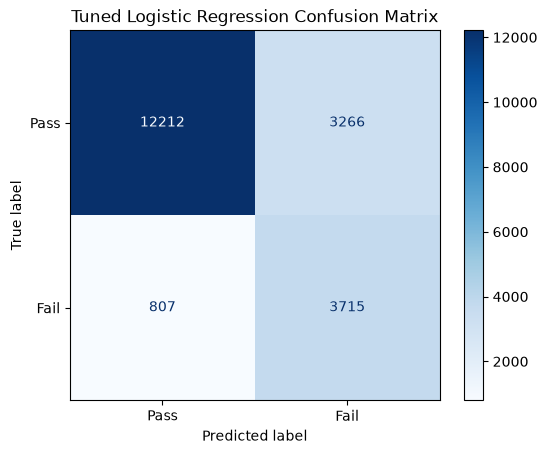

In [12]:
tuned_predictions = best_logistic.predict(X_test_scaled)
tuned_probabilities = best_logistic.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Precision for Fail:", round(precision_score(y_test, tuned_predictions), 4))
print("Recall for Fail:", round(recall_score(y_test, tuned_predictions), 4))
print("F1 for Fail:", round(f1_score(y_test, tuned_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test, tuned_probabilities), 4))
print()
print(classification_report(
    y_test, tuned_predictions, target_names=["Pass", "Fail"], zero_division=0
))

matrix = confusion_matrix(y_test, tuned_predictions)
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=matrix, display_labels=["Pass", "Fail"]
)
display_matrix.plot(cmap="Blues")
plt.title("Tuned Logistic Regression Confusion Matrix")
plt.show()


In [13]:
train_predictions = best_logistic.predict(X_train_scaled)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, tuned_predictions)
train_f1 = f1_score(y_train, train_predictions)
test_f1 = f1_score(y_test, tuned_predictions)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))
print("Accuracy Gap:", round(train_accuracy - test_accuracy, 4))
print()
print("Training F1 for Fail:", round(train_f1, 4))
print("Testing F1 for Fail:", round(test_f1, 4))
print("F1 Gap:", round(train_f1 - test_f1, 4))
print()
print("Cross-Validation F1:", round(logistic_grid.best_score_, 4))


Training Accuracy: 0.7997
Testing Accuracy: 0.7964
Accuracy Gap: 0.0033

Training F1 for Fail: 0.6487
Testing F1 for Fail: 0.6459
F1 Gap: 0.0028

Cross-Validation F1: 0.6483


In [14]:
calibrated_logistic = CalibratedClassifierCV(
    estimator=best_logistic,
    method="sigmoid",
    cv=3
)

calibrated_logistic.fit(X_train_scaled, y_train)

calibrated_failure_probabilities = calibrated_logistic.predict_proba(
    X_test_scaled
)[:, 1]

print("Uncalibrated Brier score:", round(
    brier_score_loss(y_test, tuned_probabilities), 4
))
print("Calibrated Brier score:", round(
    brier_score_loss(y_test, calibrated_failure_probabilities), 4
))
print("Calibrated ROC-AUC:", round(
    roc_auc_score(y_test, calibrated_failure_probabilities), 4
))
print("Calibrated PR-AUC:", round(
    average_precision_score(y_test, calibrated_failure_probabilities), 4
))


Uncalibrated Brier score: 0.1383
Calibrated Brier score: 0.1066
Calibrated ROC-AUC: 0.89
Calibrated PR-AUC: 0.7202


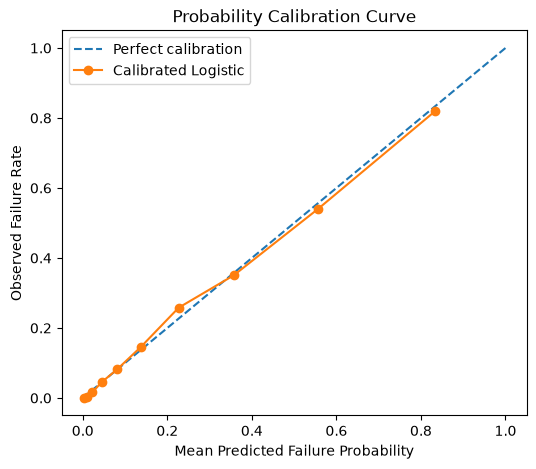

In [15]:
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    calibrated_failure_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(mean_predicted, fraction_positive, marker="o", label="Calibrated Logistic")
plt.xlabel("Mean Predicted Failure Probability")
plt.ylabel("Observed Failure Rate")
plt.title("Probability Calibration Curve")
plt.legend()
plt.show()


##  Classification at the Default Threshold

The official Pass/Fail prediction below uses the default threshold of 0.50. Threshold optimization is deliberately left for a separate validation exercise rather than repeatedly selecting a threshold on the test set.


In [16]:
classification_threshold = 0.50

calibrated_predictions = (
    calibrated_failure_probabilities >= classification_threshold
).astype(int)

print("Threshold:", classification_threshold)
print("Precision for Fail:", round(
    precision_score(y_test, calibrated_predictions, zero_division=0), 4
))
print("Recall for Fail:", round(
    recall_score(y_test, calibrated_predictions, zero_division=0), 4
))
print("F1 for Fail:", round(
    f1_score(y_test, calibrated_predictions, zero_division=0), 4
))
print()
print(classification_report(
    y_test, calibrated_predictions, target_names=["Pass", "Fail"], zero_division=0
))


Threshold: 0.5
Precision for Fail: 0.7118
Recall for Fail: 0.5429
F1 for Fail: 0.616

              precision    recall  f1-score   support

        Pass       0.88      0.94      0.90     15478
        Fail       0.71      0.54      0.62      4522

    accuracy                           0.85     20000
   macro avg       0.79      0.74      0.76     20000
weighted avg       0.84      0.85      0.84     20000



## Convert Probabilities into Risk Levels

Initial operational bands:

- Low Risk: below 30%
- Medium Risk: 30% to below 60%
- High Risk: 60% or higher

These are project risk bands, not guarantees and not the same as the classification threshold.


In [17]:
def get_risk_level(failure_probability):
    if failure_probability < 0.30:
        return "Low Risk"
    elif failure_probability < 0.60:
        return "Medium Risk"
    return "High Risk"


In [18]:
final_student_results = pd.DataFrame({
    "student_id": df.loc[X_test.index, "student_id"].values,
    "actual_status": y_test.map({0: "Pass", 1: "Fail"}).values,
    "predicted_status": pd.Series(calibrated_predictions).map(
        {0: "Pass", 1: "Fail"}
    ).values,
    "failure_probability": calibrated_failure_probabilities,
    "failure_percentage": (calibrated_failure_probabilities * 100).round(2)
})

final_student_results["risk_level"] = (
    final_student_results["failure_probability"].apply(get_risk_level)
)

final_student_results = final_student_results.sort_values(
    "failure_probability", ascending=False
).reset_index(drop=True)

display(final_student_results.head(20))


,student_id,actual_status,predicted_status,failure_probability,failure_percentage,risk_level
0,STU_047333,Fail,Fail,0.997386,99.74,High Risk
1,STU_072723,Fail,Fail,0.996619,99.66,High Risk
2,STU_073301,Fail,Fail,0.996371,99.64,High Risk
3,STU_016076,Fail,Fail,0.994397,99.44,High Risk
4,STU_012469,Fail,Fail,0.993804,99.38,High Risk
5,STU_071256,Fail,Fail,0.993776,99.38,High Risk
6,STU_008942,Fail,Fail,0.993589,99.36,High Risk
7,STU_066795,Fail,Fail,0.993468,99.35,High Risk
8,STU_059758,Fail,Fail,0.993198,99.32,High Risk
9,STU_047540,Fail,Fail,0.992902,99.29,High Risk


In [19]:
risk_summary = (
    final_student_results["risk_level"]
    .value_counts()
    .reindex(["Low Risk", "Medium Risk", "High Risk"], fill_value=0)
    .rename_axis("risk_level")
    .reset_index(name="student_count")
)

risk_summary["percentage_of_test_students"] = (
    risk_summary["student_count"] / len(final_student_results) * 100
).round(2)

display(risk_summary)


,risk_level,student_count,percentage_of_test_students
0,Low Risk,14233,71.17
1,Medium Risk,3160,15.80
2,High Risk,2607,13.04


In [20]:
student_number = 0
student = final_student_results.iloc[student_number]

print("Student ID:", student["student_id"])
print("Actual status:", student["actual_status"])
print("Predicted status:", student["predicted_status"])
print("Failure probability:", round(student["failure_probability"], 4))
print("Failure percentage:", str(student["failure_percentage"]) + "%")
print("Risk level:", student["risk_level"])


Student ID: STU_047333
Actual status: Fail
Predicted status: Fail
Failure probability: 0.9974
Failure percentage: 99.74%
Risk level: High Risk


In [21]:
final_student_results.to_csv(
    "EduPredict_Logistic_Student_Risk_Results.csv", index=False
)
risk_summary.to_csv(
    "EduPredict_Logistic_Risk_Summary.csv", index=False
)

joblib.dump(calibrated_logistic, "EduPredict_Calibrated_Logistic_Model.pkl")
joblib.dump(scaler, "EduPredict_Scaler.pkl")
joblib.dump(X_train_scaled.columns.tolist(), "EduPredict_Feature_Columns.pkl")

print("Risk results, summary, calibrated model, scaler, and feature columns were saved.")


Risk results, summary, calibrated model, scaler, and feature columns were saved.


In [22]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles saved in:")
print(
    os.path.abspath(
        "EduPredict_Logistic_Student_Risk_Results.csv"
    )
)

print(
    os.path.abspath(
        "EduPredict_Logistic_Risk_Summary.csv"
    )
)

Current working directory:
c:\Users\nadee\Downloads

Files saved in:
c:\Users\nadee\Downloads\EduPredict_Logistic_Student_Risk_Results.csv
c:\Users\nadee\Downloads\EduPredict_Logistic_Risk_Summary.csv
